# Polmonite da radiografie (PneumoniaMNIST) - notebook ordinato
Eseguire le celle dall'alto in basso (Runtime > Cambia tipo di runtime > GPU).

Con `RIADDESTRA = False` (consigliato) vengono usati i pesi gia' addestrati: non si addestra nulla.

## 0. Installazione, Drive e pesi
Copiare prima i due file `.pth` in `MyDrive/esame_pneumonia/`.

In [1]:
!pip install -q medmnist==3.0.2 monai lime

In [3]:
from google.colab import drive
from pathlib import Path
drive.mount('/content/drive')

BASE = Path('/content/drive/MyDrive/Colab Notebooks/esame_pneumonia')
RESULTS = BASE / 'results_notebook'
RESULTS.mkdir(parents=True, exist_ok=True)
RIADDESTRA = False

for name in ['best_pneumonia_cnn.pth', 'best_pneumonia_vit.pth']:
    print(name, 'trovato' if (BASE / name).is_file() else 'MANCANTE')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
best_pneumonia_cnn.pth trovato
best_pneumonia_vit.pth trovato


## 1. Import e riproducibilita'

In [21]:
import os
import random
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim
from torch.amp import autocast, GradScaler

import monai
import medmnist
from medmnist import INFO

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    average_precision_score,
    brier_score_loss
)

from tqdm.auto import tqdm
from sklearn.calibration import calibration_curve

from sklearn.metrics import ConfusionMatrixDisplay
from torchvision.models import vit_b_16, ViT_B_16_Weights
from monai.transforms import (
    Compose,
    EnsureChannelFirst,
    ScaleIntensity,
    Resize,
    NormalizeIntensity,
    RandFlip,
    EnsureType
)

from torch.utils.data import Dataset, DataLoader

# Configurazione della riproducibilità
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# Selezione del dispositivo di calcolo
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Python:", platform.python_version())
print("PyTorch:", torch.__version__)
print("MONAI:", monai.__version__)
print("MedMNIST:", medmnist.__version__)
print("Dispositivo:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("ATTENZIONE: GPU non disponibile. L'addestramento potrebbe essere lento.")

Python: 3.13.18
PyTorch: 2.14.1+cpu
MONAI: 1.6.2
MedMNIST: 3.0.2
Dispositivo: cpu
ATTENZIONE: GPU non disponibile. L'addestramento potrebbe essere lento.


## 2. Configurazione e dataset

In [5]:
# Configurazione del dataset
DATA_FLAG = "pneumoniamnist"
DATA_ROOT = "/content/medical_imaging_data"

# Iperparametri di addestramento
BATCH_SIZE = 64
NUM_EPOCHS = 5
LEARNING_RATE = 1e-4

# Parametri del problema
NUM_CLASSES = 2
IMAGE_SIZE = 224

print("Dataset:", DATA_FLAG)
print("Percorso dataset:", DATA_ROOT)
print("Numero classi:", NUM_CLASSES)
print("Dimensione immagini:", IMAGE_SIZE)
print("Batch size:", BATCH_SIZE)
print("Epoche:", NUM_EPOCHS)
print("Learning rate:", LEARNING_RATE)

Dataset: pneumoniamnist
Percorso dataset: /content/medical_imaging_data
Numero classi: 2
Dimensione immagini: 224
Batch size: 64
Epoche: 5
Learning rate: 0.0001


In [6]:
info = INFO[DATA_FLAG]

# Creazione della directory in cui salvare il dataset
os.makedirs(DATA_ROOT, exist_ok=True)

print("Descrizione:", info["description"])
print("Classi:", info["label"])
print("Numero di canali:", info["n_channels"])
print("Classe Python:", info["python_class"])

# Individuazione dinamica della classe del dataset
DataClass = getattr(medmnist, info["python_class"])

# Download e caricamento degli split ufficiali
train_dataset = DataClass(
    split="train",
    root=DATA_ROOT,
    download=True,
    as_rgb=True
)

val_dataset = DataClass(
    split="val",
    root=DATA_ROOT,
    download=True,
    as_rgb=True
)

test_dataset = DataClass(
    split="test",
    root=DATA_ROOT,
    download=True,
    as_rgb=True
)

# Riepilogo delle dimensioni dei dataset
print("\nDataset caricato correttamente!")
print(f"Training set:   {len(train_dataset)} immagini")
print(f"Validation set: {len(val_dataset)} immagini")
print(f"Test set:       {len(test_dataset)} immagini")

Descrizione: The PneumoniaMNIST is based on a prior dataset of 5,856 pediatric chest X-Ray images. The task is binary-class classification of pneumonia against normal. We split the source training set with a ratio of 9:1 into training and validation set and use its source validation set as the test set. The source images are gray-scale, and their sizes are (384−2,916)×(127−2,713). We center-crop the images and resize them into 1×28×28.
Classi: {'0': 'normal', '1': 'pneumonia'}
Numero di canali: 1
Classe Python: PneumoniaMNIST

Dataset caricato correttamente!
Training set:   4708 immagini
Validation set: 524 immagini
Test set:       624 immagini


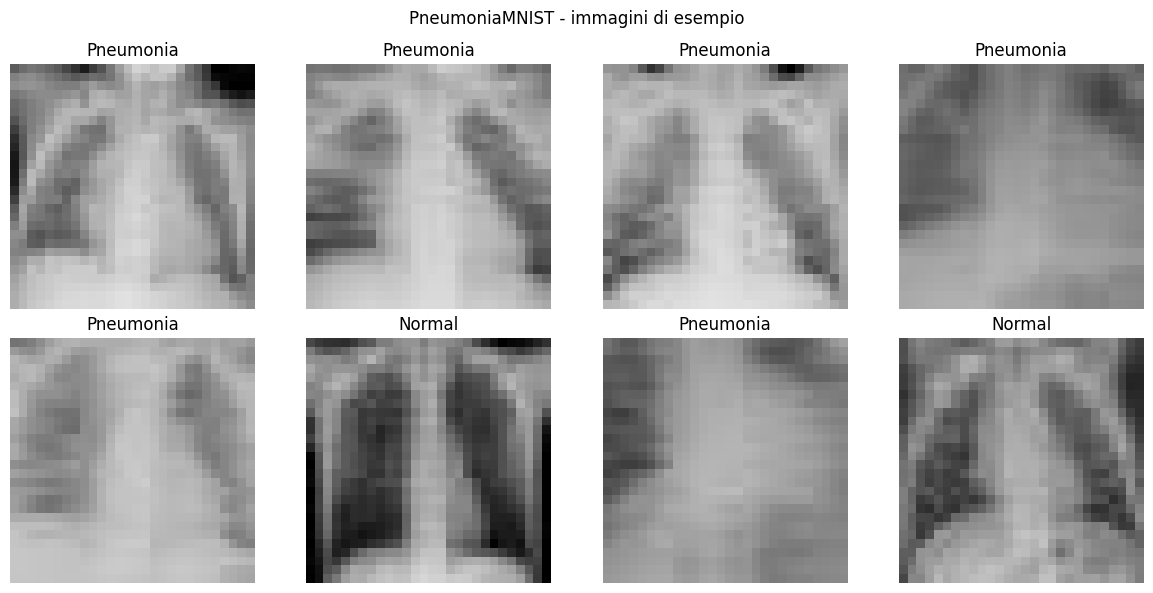

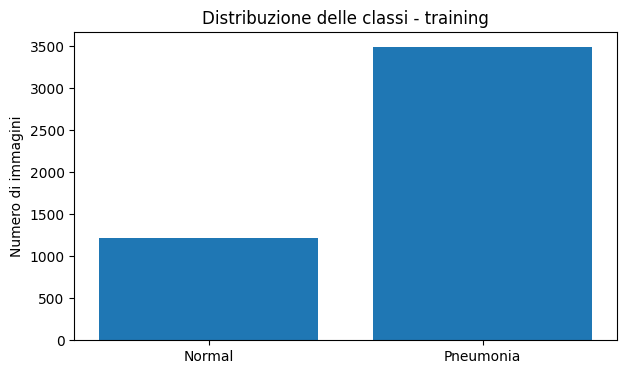

In [19]:
class_names = ["Normal", "Pneumonia"]

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax, idx in zip(axes.flat, range(8)):
    image, label = train_dataset[idx]
    ax.imshow(image)
    ax.set_title(class_names[int(label[0])])
    ax.axis("off")
plt.suptitle("PneumoniaMNIST - immagini di esempio")
plt.tight_layout()
plt.show()

counts = np.bincount(train_dataset.labels.flatten())
plt.figure(figsize=(7, 4))
plt.bar(class_names, counts)
plt.ylabel("Numero di immagini")
plt.title("Distribuzione delle classi - training")
plt.show()

## 3. Controllo qualita' dei dati

In [7]:
import hashlib

splits = {'train': train_dataset, 'val': val_dataset, 'test': test_dataset}
hashes, rows = {}, []
for name, ds in splits.items():
    imgs, y = ds.imgs, ds.labels.flatten()
    hashes[name] = [hashlib.md5(im.tobytes()).hexdigest() for im in imgs]
    flat = imgs.reshape(len(imgs), -1)
    rows.append({'split': name, 'immagini': len(imgs),
                 'normali': int((y == 0).sum()), 'polmoniti': int((y == 1).sum()),
                 'duplicati_interni': len(imgs) - len(set(hashes[name])),
                 'immagini_uniformi': int((flat.std(axis=1) == 0).sum()),
                 'min': int(imgs.min()), 'max': int(imgs.max())})
for a, b in [('train', 'val'), ('train', 'test'), ('val', 'test')]:
    print(f'Immagini identiche {a}/{b}:', len(set(hashes[a]) & set(hashes[b])))
qc = pd.DataFrame(rows)
qc.to_csv(RESULTS / 'quality_control.csv', index=False)
qc

Immagini identiche train/val: 8
Immagini identiche train/test: 0
Immagini identiche val/test: 0


,split,immagini,normali,polmoniti,duplicati_interni,immagini_uniformi,min,max
0,train,4708,1214,3494,18,0,0,255
1,val,524,135,389,0,0,0,255
2,test,624,234,390,3,0,0,254


## 4. Preprocessing MONAI e DataLoader

In [8]:
# Trasformazioni per il training
train_transforms = Compose([
    EnsureChannelFirst(channel_dim=-1),
    ScaleIntensity(),
    Resize(spatial_size=(IMAGE_SIZE, IMAGE_SIZE)),
    RandFlip(prob=0.5, spatial_axis=1),
    EnsureType(dtype=torch.float32)
])

# Trasformazioni per validation e test
eval_transforms = Compose([
    EnsureChannelFirst(channel_dim=-1),
    ScaleIntensity(),
    Resize(spatial_size=(IMAGE_SIZE, IMAGE_SIZE)),
    EnsureType(dtype=torch.float32)
])

In [9]:
imagenet_mean = [0.485, 0.456, 0.406]
imagenet_std = [0.229, 0.224, 0.225]

# Trasformazioni per il training
train_transforms_vit = Compose([
    EnsureChannelFirst(channel_dim=-1),
    ScaleIntensity(),
    Resize(spatial_size=(224, 224)),
    RandFlip(prob=0.5, spatial_axis=1),
    NormalizeIntensity(
        subtrahend=imagenet_mean,
        divisor=imagenet_std,
        channel_wise=True
    ),
    EnsureType(dtype=torch.float32)
])

# Trasformazioni per validation e test
eval_transforms_vit = Compose([
    EnsureChannelFirst(channel_dim=-1),
    ScaleIntensity(),
    Resize(spatial_size=(224, 224)),
    NormalizeIntensity(
        subtrahend=imagenet_mean,
        divisor=imagenet_std,
        channel_wise=True
    ),
    EnsureType(dtype=torch.float32)
])

In [10]:
class PneumoniaDataset(Dataset):

    def __init__(self, medmnist_dataset, transform=None):
        self.dataset = medmnist_dataset
        self.transform = transform

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, index):

        image, label = self.dataset[index]

        image = np.array(image)

        if self.transform:
            image = self.transform(image)

        label = torch.tensor(int(label[0]), dtype=torch.long)

        return image, label


# Creazione dei dataset con le rispettive trasformazioni

train_data = PneumoniaDataset(
    train_dataset,
    transform=train_transforms
)

val_data = PneumoniaDataset(
    val_dataset,
    transform=eval_transforms
)

test_data = PneumoniaDataset(
    test_dataset,
    transform=eval_transforms
)

print("Dataset PyTorch creati correttamente!")
print("Training:", len(train_data))
print("Validation:", len(val_data))
print("Test:", len(test_data))


# Creazione dei DataLoader

train_loader = DataLoader(
    train_data,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_data,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_data,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("DataLoader creati correttamente!")
print("Batch training:", len(train_loader))
print("Batch validation:", len(val_loader))
print("Batch test:", len(test_loader))

Dataset PyTorch creati correttamente!
Training: 4708
Validation: 524
Test: 624
DataLoader creati correttamente!
Batch training: 74
Batch validation: 9
Batch test: 10


## 5. Architetture

In [11]:
class PneumoniaCNN(nn.Module):
    """
    Rete convoluzionale personalizzata per la classificazione
    binaria delle radiografie toraciche.

    Classi:
        0: Normal
        1: Pneumonia
    """

    def __init__(self, num_classes=2):
        super().__init__()

        # Estrazione gerarchica delle caratteristiche visive
        self.features = nn.Sequential(
            # Primo blocco convoluzionale
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Secondo blocco convoluzionale
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Terzo blocco convoluzionale
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Quarto blocco convoluzionale
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        # Classificazione finale
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        """Esegue il passaggio forward della CNN."""
        return self.classifier(self.features(x))


def create_vit(num_classes=2):
    """
    Crea un Vision Transformer ViT-B/16 con testa
    di classificazione adattata al problema binario.

    Il modello viene inizializzato da zero (weights=None).
    """

    model = vit_b_16(weights=None)

    # Sostituzione della testa originale con una binaria
    in_features = model.heads.head.in_features
    model.heads.head = nn.Linear(in_features, num_classes)

    return model

## 6. Addestramento (saltato se RIADDESTRA = False)
I nuovi pesi vanno in una cartella separata: gli originali non vengono sovrascritti.

In [12]:
if RIADDESTRA:
    (BASE / 'retrain').mkdir(exist_ok=True)

    model = PneumoniaCNN(num_classes=NUM_CLASSES).to(device)

    # Funzione di perdita
    criterion = nn.CrossEntropyLoss()

    # Ottimizzatore Adam
    optimizer = optim.Adam(
        model.parameters(),
        lr=LEARNING_RATE
    )

    # Calcolo delle frequenze delle classi
    class_counts = np.bincount(train_dataset.labels.flatten())

    # Calcolo dei pesi inversamente proporzionali
    class_weights = len(train_dataset) / (NUM_CLASSES * class_counts)

    class_weights = torch.tensor(
        class_weights,
        dtype=torch.float32
    ).to(device)

    print("Numero immagini per classe:", class_counts)
    print("Pesi delle classi:", class_weights)

    # Aggiornamento della funzione di perdita
    criterion = nn.CrossEntropyLoss(weight=class_weights)

    # Liste per memorizzare le metriche
    train_losses = []
    val_losses = []

    train_accuracies = []
    val_accuracies = []

    best_val_loss = float("inf")

    for epoch in range(NUM_EPOCHS):

        # -------------------------
        # TRAINING
        # -------------------------
        model.train()

        running_loss = 0.0
        correct = 0
        total = 0

        progress_bar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{NUM_EPOCHS}")

        for images, labels in progress_bar:

            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            running_loss += loss.item() * images.size(0)

            predictions = torch.argmax(outputs, dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

            progress_bar.set_postfix(loss=loss.item())

        epoch_train_loss = running_loss / total
        epoch_train_accuracy = correct / total

        # -------------------------
        # VALIDATION
        # -------------------------
        model.eval()

        running_val_loss = 0.0
        val_correct = 0
        val_total = 0

        with torch.no_grad():

            for images, labels in val_loader:

                images = images.to(device)
                labels = labels.to(device)

                outputs = model(images)
                loss = criterion(outputs, labels)

                running_val_loss += loss.item() * images.size(0)

                predictions = torch.argmax(outputs, dim=1)

                val_correct += (predictions == labels).sum().item()
                val_total += labels.size(0)

        epoch_val_loss = running_val_loss / val_total
        epoch_val_accuracy = val_correct / val_total

        # Memorizzazione delle metriche
        train_losses.append(epoch_train_loss)
        val_losses.append(epoch_val_loss)

        train_accuracies.append(epoch_train_accuracy)
        val_accuracies.append(epoch_val_accuracy)

        # Salvataggio del modello migliore
        if epoch_val_loss < best_val_loss:

            best_val_loss = epoch_val_loss

            torch.save(
                model.state_dict(),
                str(BASE / "retrain" / "best_pneumonia_cnn.pth")
            )

        print(f"\nEpoch [{epoch+1}/{NUM_EPOCHS}]")
        print(f"Train Loss: {epoch_train_loss:.4f}")
        print(f"Train Accuracy: {epoch_train_accuracy:.4f}")
        print(f"Validation Loss: {epoch_val_loss:.4f}")
        print(f"Validation Accuracy: {epoch_val_accuracy:.4f}")

    print("\nTraining completato!")
    print("Migliore Validation Loss:", best_val_loss)

In [13]:
if RIADDESTRA:
    (BASE / 'retrain').mkdir(exist_ok=True)

    model_vit = create_vit(NUM_CLASSES).to(device)
    BATCH_SIZE_VIT, LEARNING_RATE_VIT, NUM_EPOCHS_VIT = 8, 1e-5, 5

    train_data_vit = PneumoniaDataset(
        train_dataset,
        transform=train_transforms_vit
    )

    val_data_vit = PneumoniaDataset(
        val_dataset,
        transform=eval_transforms_vit
    )

    test_data_vit = PneumoniaDataset(
        test_dataset,
        transform=eval_transforms_vit
    )

    train_loader_vit = DataLoader(
        train_data_vit,
        batch_size=BATCH_SIZE_VIT,
        shuffle=True,
        num_workers=0,
        pin_memory=True
    )

    val_loader_vit = DataLoader(
        val_data_vit,
        batch_size=BATCH_SIZE_VIT,
        shuffle=False,
        num_workers=0,
        pin_memory=True
    )

    test_loader_vit = DataLoader(
        test_data_vit,
        batch_size=BATCH_SIZE_VIT,
        shuffle=False,
        num_workers=0,
        pin_memory=True
    )

    class_counts = np.bincount(train_dataset.labels.flatten())
    class_weights = torch.tensor(len(train_dataset) / (NUM_CLASSES * class_counts), dtype=torch.float32).to(device)

    # Funzione di perdita con pesi per le due classi
    criterion_vit = nn.CrossEntropyLoss(weight=class_weights)

    # Ottimizzatore AdamW
    optimizer_vit = optim.AdamW(
        model_vit.parameters(),
        lr=LEARNING_RATE_VIT,
        weight_decay=1e-4
    )

    # Inizializziamo lo scaler per la mixed precision
    scaler = GradScaler("cuda")

    # Liste per registrare le metriche
    train_losses_vit = []
    val_losses_vit = []
    train_accuracies_vit = []
    val_accuracies_vit = []

    best_val_loss_vit = float("inf")
    best_epoch_vit = 0

    for epoch in range(NUM_EPOCHS_VIT):

        # -------------------------
        # TRAINING
        # -------------------------
        model_vit.train()

        running_loss = 0.0
        correct = 0
        total = 0

        train_bar = tqdm(
            train_loader_vit,
            desc=f"ViT Epoch {epoch+1}/{NUM_EPOCHS_VIT} - Training"
        )

        for images, labels in train_bar:

            images = images.to(device)
            labels = labels.to(device)

            optimizer_vit.zero_grad(set_to_none=True)

            with autocast(device_type="cuda", dtype=torch.float16):
                outputs = model_vit(images)
                loss = criterion_vit(outputs, labels)

            scaler.scale(loss).backward()
            scaler.step(optimizer_vit)
            scaler.update()

            running_loss += loss.item() * images.size(0)

            predictions = torch.argmax(outputs.detach(), dim=1)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)

            train_bar.set_postfix(loss=loss.item())

        epoch_train_loss = running_loss / total
        epoch_train_acc = correct / total

        # -------------------------
        # VALIDATION
        # -------------------------
        model_vit.eval()

        val_running_loss = 0.0
        val_correct = 0
        val_total = 0

        with torch.no_grad():

            for images, labels in tqdm(
                val_loader_vit,
                desc=f"ViT Epoch {epoch+1}/{NUM_EPOCHS_VIT} - Validation"
            ):

                images = images.to(device)
                labels = labels.to(device)

                with autocast(device_type="cuda", dtype=torch.float16):
                    outputs = model_vit(images)
                    loss = criterion_vit(outputs, labels)

                val_running_loss += loss.item() * images.size(0)

                predictions = torch.argmax(outputs, dim=1)
                val_correct += (predictions == labels).sum().item()
                val_total += labels.size(0)

        epoch_val_loss = val_running_loss / val_total
        epoch_val_acc = val_correct / val_total

        # Registriamo le metriche
        train_losses_vit.append(epoch_train_loss)
        val_losses_vit.append(epoch_val_loss)
        train_accuracies_vit.append(epoch_train_acc)
        val_accuracies_vit.append(epoch_val_acc)

        # Salviamo il modello migliore
        if epoch_val_loss < best_val_loss_vit:
            best_val_loss_vit = epoch_val_loss
            best_epoch_vit = epoch + 1

            torch.save(
                model_vit.state_dict(),
                str(BASE / "retrain" / "best_pneumonia_vit.pth")
            )

        print(f"\nEpoch {epoch+1}/{NUM_EPOCHS_VIT}")
        print(f"Train Loss: {epoch_train_loss:.4f}")
        print(f"Train Accuracy: {epoch_train_acc:.4f}")
        print(f"Validation Loss: {epoch_val_loss:.4f}")
        print(f"Validation Accuracy: {epoch_val_acc:.4f}")
        print("-" * 45)

    print("\nAddestramento ViT completato!")
    print("Migliore epoca:", best_epoch_vit)
    print(f"Migliore Validation Loss: {best_val_loss_vit:.4f}")

## 7. Caricamento dei pesi originali e valutazione

In [14]:
cnn_model = PneumoniaCNN().to(device)
vit_model = create_vit().to(device)
cnn_model.load_state_dict(torch.load(BASE / 'best_pneumonia_cnn.pth', map_location=device, weights_only=True))
vit_model.load_state_dict(torch.load(BASE / 'best_pneumonia_vit.pth', map_location=device, weights_only=True))
cnn_model.eval(); vit_model.eval()

def predict_probs(model, transform):
    loader = DataLoader(PneumoniaDataset(test_dataset, transform), batch_size=64, shuffle=False)
    out = []
    with torch.no_grad():
        for images, _ in loader:
            out.extend(torch.softmax(model(images.to(device)), dim=1)[:, 1].cpu().numpy())
    return np.array(out)

y_true = test_dataset.labels.flatten()
probs = {'CNN': predict_probs(cnn_model, eval_transforms),
         'ViT': predict_probs(vit_model, eval_transforms_vit)}
for name, p in probs.items():
    print(f'{name}: ROC-AUC {roc_auc_score(y_true, p):.4f}  Brier {brier_score_loss(y_true, p):.4f}')
print('Attesi: CNN 0.9202 / 0.1101 - ViT 0.9550 / 0.0893')

CNN: ROC-AUC 0.9202  Brier 0.1101
ViT: ROC-AUC 0.9550  Brier 0.0893
Attesi: CNN 0.9202 / 0.1101 - ViT 0.9550 / 0.0893


## 8. Spiegazioni LIME
Un caso per tipo (VP, VN, FP, FN) per ciascun modello. Verde: zone a favore di *polmonite*; rosso: contrarie.

/tmp/ipykernel_3834/1155842406.py:26: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  image = np.array(eval_transforms(np.array(test_dataset[idx][0]))).transpose(1, 2, 0)


  0%|          | 0/1000 [00:00<?, ?it/s]

/tmp/ipykernel_3834/1155842406.py:26: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  image = np.array(eval_transforms(np.array(test_dataset[idx][0]))).transpose(1, 2, 0)


  0%|          | 0/1000 [00:00<?, ?it/s]

/tmp/ipykernel_3834/1155842406.py:26: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  image = np.array(eval_transforms(np.array(test_dataset[idx][0]))).transpose(1, 2, 0)


  0%|          | 0/1000 [00:00<?, ?it/s]

/tmp/ipykernel_3834/1155842406.py:26: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  image = np.array(eval_transforms(np.array(test_dataset[idx][0]))).transpose(1, 2, 0)


  0%|          | 0/1000 [00:00<?, ?it/s]

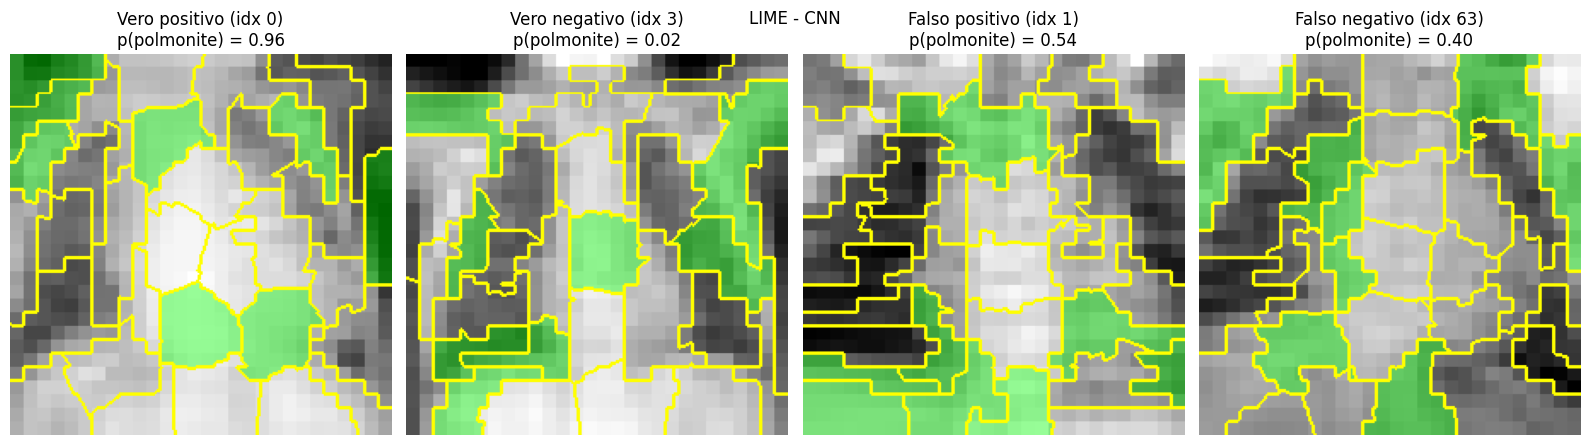

/tmp/ipykernel_3834/1155842406.py:26: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  image = np.array(eval_transforms(np.array(test_dataset[idx][0]))).transpose(1, 2, 0)


  0%|          | 0/1000 [00:00<?, ?it/s]

/tmp/ipykernel_3834/1155842406.py:26: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  image = np.array(eval_transforms(np.array(test_dataset[idx][0]))).transpose(1, 2, 0)


  0%|          | 0/1000 [00:00<?, ?it/s]

/tmp/ipykernel_3834/1155842406.py:26: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  image = np.array(eval_transforms(np.array(test_dataset[idx][0]))).transpose(1, 2, 0)


  0%|          | 0/1000 [00:00<?, ?it/s]

/tmp/ipykernel_3834/1155842406.py:26: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  image = np.array(eval_transforms(np.array(test_dataset[idx][0]))).transpose(1, 2, 0)


  0%|          | 0/1000 [00:00<?, ?it/s]

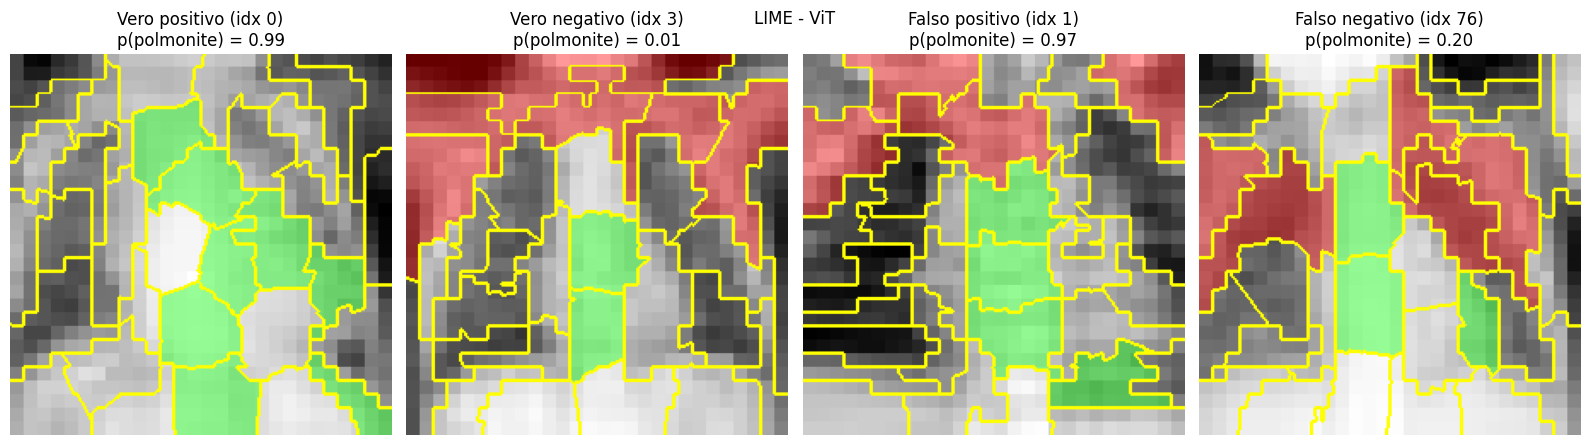

In [15]:
from lime import lime_image
from skimage.segmentation import slic, mark_boundaries

MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)

def make_predict_fn(name):
    model = cnn_model if name == 'CNN' else vit_model
    def predict_fn(images):
        x = torch.tensor(np.array(images), dtype=torch.float32).permute(0, 3, 1, 2)
        if name == 'ViT':
            x = (x - MEAN) / STD
        with torch.no_grad():
            return torch.softmax(model(x.to(device)), dim=1).cpu().numpy()
    return predict_fn

explainer = lime_image.LimeImageExplainer(random_state=SEED)

for name, p in probs.items():
    pred = (p > 0.5).astype(int)
    cases = {'Vero positivo': (1, 1), 'Vero negativo': (0, 0),
             'Falso positivo': (0, 1), 'Falso negativo': (1, 0)}
    fig, axes = plt.subplots(1, 4, figsize=(16, 4.5))
    for ax, (title, (t, d)) in zip(axes, cases.items()):
        idx = int(np.where((y_true == t) & (pred == d))[0][0])
        image = np.array(eval_transforms(np.array(test_dataset[idx][0]))).transpose(1, 2, 0)
        exp = explainer.explain_instance(
            image.astype(np.float64), make_predict_fn(name), labels=(1,), top_labels=None,
            hide_color=0, num_samples=1000, batch_size=32, random_seed=SEED,
            segmentation_fn=lambda im: slic(im, n_segments=40, compactness=10, start_label=0))
        weights = dict(exp.local_exp[1])
        top = sorted(weights, key=lambda s: abs(weights[s]), reverse=True)[:8]
        overlay = image.copy()
        for s in top:
            color = np.array([0, 1, 0]) if weights[s] > 0 else np.array([1, 0, 0])
            overlay[exp.segments == s] = 0.6 * overlay[exp.segments == s] + 0.4 * color
        ax.imshow(np.clip(mark_boundaries(overlay, exp.segments), 0, 1))
        ax.set_title(f'{title} (idx {idx})\np(polmonite) = {p[idx]:.2f}')
        ax.axis('off')
    fig.suptitle(f'LIME - {name}')
    fig.tight_layout()
    fig.savefig(RESULTS / f'lime_{name.lower()}.png', dpi=200, bbox_inches='tight')
    plt.show()

In [ ]:
def expected_calibration_error(y, p, n_bins=10):

    bin_edges = np.linspace(0, 1, n_bins + 1)
    ece = 0.0

    for i in range(n_bins):

        # Individua le probabilità appartenenti all'intervallo
        if i == n_bins - 1:
            mask = (p >= bin_edges[i]) & (p <= bin_edges[i + 1])
        else:
            mask = (p >= bin_edges[i]) & (p < bin_edges[i + 1])

        if np.any(mask):

            # Frequenza reale di polmonite nel bin
            accuracy_bin = np.mean(y[mask])

            # Probabilità media predetta nel bin
            confidence_bin = np.mean(p[mask])

            # Peso proporzionale al numero di immagini
            bin_weight = np.sum(mask) / len(y)

            ece += bin_weight * abs(accuracy_bin - confidence_bin)

    return ece


def metrics(y, p):

    d = (p > 0.5).astype(int)

    tn, fp, fn, tp = confusion_matrix(y, d).ravel()

    return {
        'Accuracy': accuracy_score(y, d),
        'Precision': precision_score(y, d),
        'Sensibilita': recall_score(y, d),
        'Specificita': tn / (tn + fp),
        'F1': f1_score(y, d),
        'ROC-AUC': roc_auc_score(y, p),
        'AUC-PR': average_precision_score(y, p),
        'Brier': brier_score_loss(y, p),
        'ECE': expected_calibration_error(y, p, n_bins=10)
    }

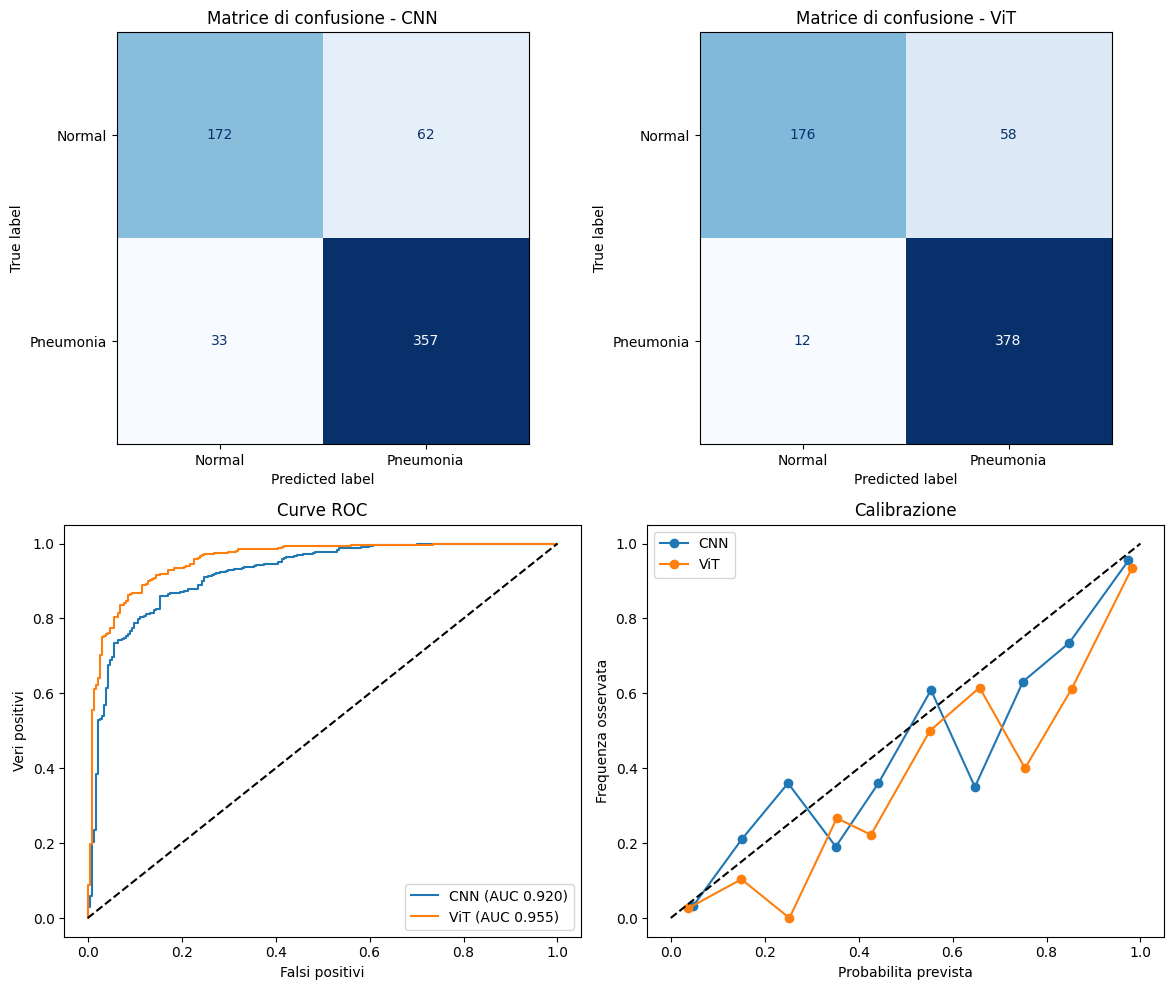

In [17]:
from sklearn.metrics import roc_curve

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for ax, (name, p) in zip(axes[0], probs.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_true, (p > 0.5).astype(int), display_labels=['Normal', 'Pneumonia'],
        ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(f'Matrice di confusione - {name}')

for name, p in probs.items():
    fpr, tpr, _ = roc_curve(y_true, p)
    axes[1, 0].plot(fpr, tpr, label=f'{name} (AUC {roc_auc_score(y_true, p):.3f})')
    obs, pred = calibration_curve(y_true, p, n_bins=10)
    axes[1, 1].plot(pred, obs, marker='o', label=name)

for ax, title, xl, yl in [(axes[1, 0], 'Curve ROC', 'Falsi positivi', 'Veri positivi'),
                          (axes[1, 1], 'Calibrazione', 'Probabilita prevista', 'Frequenza osservata')]:
    ax.plot([0, 1], [0, 1], 'k--')
    ax.set(title=title, xlabel=xl, ylabel=yl)
    ax.legend()

fig.tight_layout()
fig.savefig(RESULTS / 'valutazione.png', dpi=200)
plt.show()

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


/tmp/ipykernel_3834/517501988.py:11: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  rgb = np.array(eval_transforms(raw), dtype=np.float32).transpose(1, 2, 0)
/tmp/ipykernel_3834/517501988.py:19: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  x = torch.tensor(np.array(tf(raw))).unsqueeze(0).to(device)


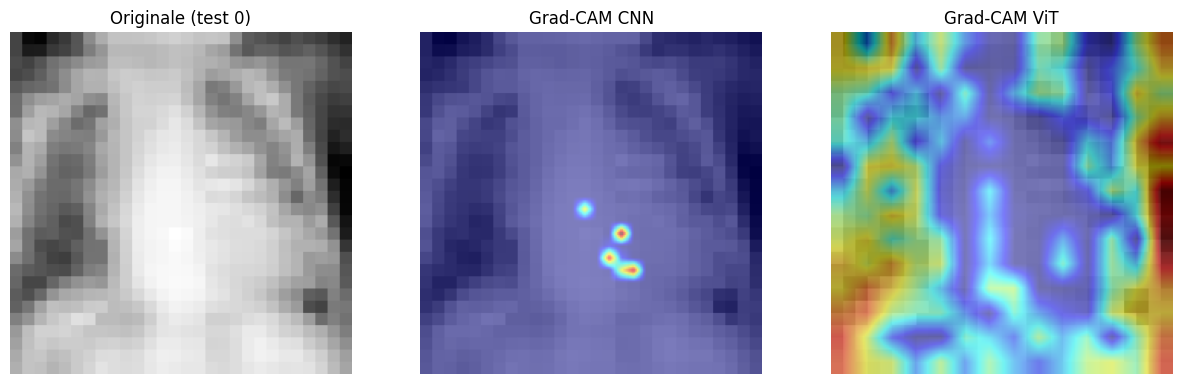

In [18]:
!pip install -q grad-cam
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image

def reshape_vit(t):
    t = t[:, 1:, :]  # esclude il token CLS
    return t.reshape(t.size(0), 14, 14, t.size(2)).permute(0, 3, 1, 2)

raw = np.array(test_dataset[0][0])
rgb = np.array(eval_transforms(raw), dtype=np.float32).transpose(1, 2, 0)

setups = [('CNN', cnn_model, eval_transforms, cnn_model.features[12], None),
          ('ViT', vit_model, eval_transforms_vit, vit_model.encoder.layers[-1].ln_1, reshape_vit)]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(rgb); axes[0].set_title('Originale (test 0)')
for ax, (name, model, tf, layer, reshape) in zip(axes[1:], setups):
    x = torch.tensor(np.array(tf(raw))).unsqueeze(0).to(device)
    with GradCAM(model=model, target_layers=[layer], reshape_transform=reshape) as cam:
        heat = cam(input_tensor=x, targets=[ClassifierOutputTarget(1)])[0]
    ax.imshow(show_cam_on_image(rgb, heat, use_rgb=True)); ax.set_title(f'Grad-CAM {name}')
for ax in axes:
    ax.axis('off')
fig.savefig(RESULTS / 'gradcam.png', dpi=200, bbox_inches='tight')
plt.show()

In [20]:
!pip install -q pydicom
from pydicom.dataset import FileDataset, FileMetaDataset
from pydicom.uid import generate_uid, ExplicitVRLittleEndian, SecondaryCaptureImageStorage

pixels = np.asarray(test_dataset[0][0].convert("L"), dtype=np.uint8)
path = str(RESULTS / "test_xray.dcm")

meta = FileMetaDataset()
meta.MediaStorageSOPClassUID = SecondaryCaptureImageStorage
meta.MediaStorageSOPInstanceUID = generate_uid()
meta.TransferSyntaxUID = ExplicitVRLittleEndian

ds = FileDataset(path, {}, file_meta=meta, preamble=b"\0" * 128)
ds.SOPClassUID = SecondaryCaptureImageStorage
ds.SOPInstanceUID = meta.MediaStorageSOPInstanceUID
ds.StudyInstanceUID, ds.SeriesInstanceUID = generate_uid(), generate_uid()
ds.PatientName, ds.PatientID, ds.PatientSex = "ANONYMIZED", "TEST-001", "O"  # dati fittizi
ds.Modality, ds.ConversionType = "OT", "WSD"
ds.Rows, ds.Columns = pixels.shape
ds.SamplesPerPixel, ds.PhotometricInterpretation = 1, "MONOCHROME2"
ds.BitsAllocated, ds.BitsStored, ds.HighBit, ds.PixelRepresentation = 8, 8, 7, 0
ds.PixelData = pixels.tobytes()
ds.save_as(path, enforce_file_format=True)

check = pydicom.dcmread(path) if "pydicom" in globals() else __import__("pydicom").dcmread(path)
print("DICOM creato:", check.Rows, "x", check.Columns)
print("Pixel identici:", np.array_equal(check.pixel_array, pixels))

DICOM creato: 28 x 28
Pixel identici: True
